# Stage 4 – CNN Training and 128-Dimensional Feature Extraction

**Research:** An Unsupervised Graph-Based Framework for Adversarial Attack Detection and Severity Estimation in Deep Learning-Based Alzheimer’s MRI Classification.

## Purpose
Train a four-convolutional-layer CNN on the Stage 3 training split, monitor validation performance, evaluate the selected checkpoint on the held-out test split, and extract a 128-dimensional embedding for every image. These embeddings will be used in Stage 5 for graph construction.

## Manuscript-aligned settings
- Four convolutional layers
- 128-dimensional feature embedding
- Adam optimizer, learning rate 0.001
- Batch size 32
- 50 epochs
- Dropout 0.5

## Explicit implementation choices (not specified in the manuscript)
The manuscript does not fully specify convolution channel counts, kernel sizes, pooling arrangement, or the exact layer at which the 128-D embedding is taken. This notebook uses four 3×3 convolutional layers with 32, 64, 128 and 256 channels, each followed by ReLU and 2×2 max pooling. Adaptive average pooling feeds a 128-unit fully connected embedding layer. Dropout (0.5) is applied before the four-class classification head. These choices must be documented as implementation details, not represented as verbatim manuscript specifications.

No class weighting or data augmentation is introduced in this stage, because these are not specified in the manuscript. The class imbalance should therefore be considered when interpreting the CNN classification results.

**Important:** This is a supervised CNN training step to obtain task-related image embeddings. The held-out test set is not used for model selection. The best checkpoint is selected using validation loss.

## 1. Set up Google Colab

In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU). GPU is recommended but not mandatory.

Then run the upload cell and select your **Stage3_Preprocessing_Outputs.zip** created at the end of Stage 3.

In [4]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Stage3_Preprocessing_Outputs.zip to Stage3_Preprocessing_Outputs.zip
Uploaded: ['Stage3_Preprocessing_Outputs.zip']


## 2. Install/import dependencies and set reproducibility

In [5]:
import os, glob, zipfile, json, random, shutil, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 3. Extract Stage 3 outputs and inspect files

In [6]:
zip_files = [f for f in uploaded if f.lower().endswith(".zip")]
if not zip_files:
    raise FileNotFoundError("Upload Stage3_Preprocessing_Outputs.zip.")
STAGE3_ZIP = "/content/" + zip_files[0]
STAGE3_DIR = "/content/stage3_preprocessed"
os.makedirs(STAGE3_DIR, exist_ok=True)

with zipfile.ZipFile(STAGE3_ZIP, "r") as zf:
    zf.extractall(STAGE3_DIR)

for root, dirs, filenames in os.walk(STAGE3_DIR):
    for name in filenames:
        print(os.path.relpath(os.path.join(root, name), STAGE3_DIR))

alzheimer_images_uint8.npz
class_distribution_by_split.csv
split_manifest.csv
preprocessing_config.json


## 4. Load the exact Stage 3 arrays and split manifest

In [7]:
npz_candidates = glob.glob(STAGE3_DIR + "/**/alzheimer_images_uint8.npz", recursive=True)
manifest_candidates = glob.glob(STAGE3_DIR + "/**/split_manifest.csv", recursive=True)
config_candidates = glob.glob(STAGE3_DIR + "/**/preprocessing_config.json", recursive=True)

if not npz_candidates or not manifest_candidates:
    raise FileNotFoundError("Expected alzheimer_images_uint8.npz and split_manifest.csv inside Stage 3 ZIP.")

npz_path = npz_candidates[0]
manifest_path = manifest_candidates[0]

with np.load(npz_path, allow_pickle=False) as data:
    X_uint8 = data["X"]
    y = data["y"].astype(np.int64)
    class_names = data["class_names"].astype(str)

manifest = pd.read_csv(manifest_path)

print("X shape:", X_uint8.shape, "dtype:", X_uint8.dtype)
print("y shape:", y.shape, "dtype:", y.dtype)
print("Class names in saved archive:", class_names.tolist())
print("Manifest columns:", manifest.columns.tolist())
print("Manifest rows:", len(manifest))

assert X_uint8.shape == (6400, 128, 128), "Unexpected image array shape; stop and inspect Stage 3 output."
assert len(y) == len(manifest) == len(X_uint8), "Array, labels and manifest lengths differ."
assert set(manifest["split"].unique()) == {"train", "validation", "test"}
assert "label_id" in manifest.columns and "label" in manifest.columns
assert np.array_equal(y, manifest["label_id"].to_numpy(dtype=np.int64)), "Label array and manifest label_id do not match."

X shape: (6400, 128, 128) dtype: uint8
y shape: (6400,) dtype: int64
Class names in saved archive: ['Mild Demented', 'Moderate Demented', 'Non-Demented', 'Very Mild Demented']
Manifest columns: ['source_path', 'label', 'label_id', 'split']
Manifest rows: 6400


## 5. Create tensors and DataLoaders

In [8]:
# Convert grayscale images from NHW uint8 to N1HW float32 in [0,1].
X = torch.from_numpy(X_uint8).float().div(255.0).unsqueeze(1)
y_tensor = torch.from_numpy(y).long()

train_idx = np.flatnonzero(manifest["split"].to_numpy() == "train")
val_idx = np.flatnonzero(manifest["split"].to_numpy() == "validation")
test_idx = np.flatnonzero(manifest["split"].to_numpy() == "test")

BATCH_SIZE = 32

train_ds = TensorDataset(X[train_idx], y_tensor[train_idx])
val_ds = TensorDataset(X[val_idx], y_tensor[val_idx])
test_ds = TensorDataset(X[test_idx], y_tensor[test_idx])

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Testing images:", len(test_ds))
print("Input tensor shape (one batch):", next(iter(train_loader))[0].shape)

Training images: 4480
Validation images: 960
Testing images: 960
Input tensor shape (one batch): torch.Size([32, 1, 128, 128])


## 6. Define the four-convolutional-layer CNN

In [9]:
class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, embedding_dim=128, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.embedding = nn.Linear(256, embedding_dim)
        self.embedding_activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, x, return_embedding=False):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        z = self.embedding_activation(self.embedding(x))
        logits = self.classifier(self.dropout(z))
        if return_embedding:
            return logits, z
        return logits

model = AlzheimerCNN(
    num_classes=len(class_names),
    embedding_dim=128,
    dropout=0.5
).to(device)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# Shape check only; this does not train the network.
with torch.no_grad():
    sample_logits, sample_embedding = model(torch.zeros(2, 1, 128, 128, device=device), return_embedding=True)
print("Logit shape:", tuple(sample_logits.shape))
print("Embedding shape:", tuple(sample_embedding.shape))
assert sample_embedding.shape == (2, 128)

AlzheimerCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (global_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (embedding): Linear(in_features=256, out_features=128, bias=True)
  (embedding_activation): ReLU(inplace=True)
  (dropout): Dropout(p=0.5, inplace=

## 7. Configure loss function and Adam optimizer

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 50
BEST_MODEL_PATH = "/content/best_alzheimer_cnn.pth"

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate:", 0.001)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Loss: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Batch size: 32
Epochs: 50


## 8. Define training and validation functions

In [11]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_true, all_pred = [], []

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        all_true.extend(yb.detach().cpu().numpy().tolist())
        all_pred.extend(preds.detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_true, all_pred)
    return avg_loss, acc

## 9. Train for up to 50 epochs and select best validation checkpoint

In [12]:
import time

history = []
best_val_loss = float("inf")
best_epoch = None
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "validation_loss": val_loss,
        "validation_accuracy": val_acc
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "validation_loss": val_loss,
            "class_names": class_names.tolist(),
            "seed": SEED,
            "architecture": "4 convolutional layers; channels 32,64,128,256; 128-D embedding",
            "hyperparameters": {
                "learning_rate": 0.001,
                "batch_size": 32,
                "epochs_requested": 50,
                "dropout": 0.5
            }
        }, BEST_MODEL_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, train acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f}, val acc {val_acc:.4f}"
    )

history_df = pd.DataFrame(history)
print(f"\nBest validation-loss checkpoint: epoch {best_epoch}, val loss {best_val_loss:.4f}")
print(f"Training time: {(time.time()-start_time)/60:.1f} minutes")

Epoch 01/50 | train loss 1.0661, train acc 0.4835 | val loss 1.0359, val acc 0.5000
Epoch 02/50 | train loss 1.0513, train acc 0.4955 | val loss 1.0263, val acc 0.5000
Epoch 03/50 | train loss 1.0368, train acc 0.5031 | val loss 1.0343, val acc 0.5000
Epoch 04/50 | train loss 1.0374, train acc 0.4993 | val loss 1.0238, val acc 0.5000
Epoch 05/50 | train loss 1.0263, train acc 0.5002 | val loss 1.0497, val acc 0.5000
Epoch 06/50 | train loss 1.0163, train acc 0.5069 | val loss 0.9828, val acc 0.5167
Epoch 07/50 | train loss 0.9729, train acc 0.5272 | val loss 0.9437, val acc 0.5531
Epoch 08/50 | train loss 0.9409, train acc 0.5328 | val loss 0.9077, val acc 0.5656
Epoch 09/50 | train loss 0.9383, train acc 0.5473 | val loss 0.9238, val acc 0.5510
Epoch 10/50 | train loss 0.9304, train acc 0.5455 | val loss 0.9425, val acc 0.5510
Epoch 11/50 | train loss 0.9126, train acc 0.5545 | val loss 0.8782, val acc 0.5792
Epoch 12/50 | train loss 0.9064, train acc 0.5672 | val loss 0.8777, val acc

## 10. Plot training and validation curves

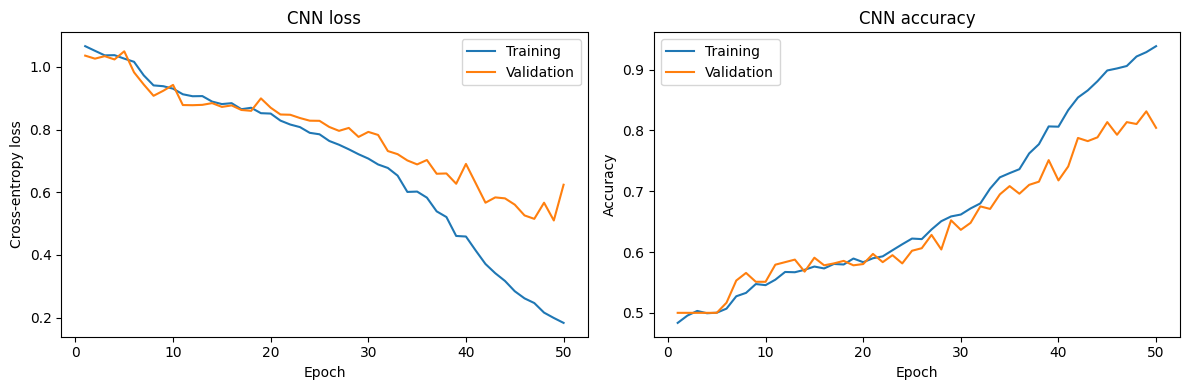

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Training")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], label="Validation")
axes[0].set_title("CNN loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_accuracy"], label="Training")
axes[1].plot(history_df["epoch"], history_df["validation_accuracy"], label="Validation")
axes[1].set_title("CNN accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Load the best checkpoint and evaluate the held-out test split

In [14]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loss, test_acc = run_epoch(model, test_loader, criterion, optimizer=None)

y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(device))
        y_true.extend(yb.numpy().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(len(class_names))), zero_division=0
)

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=list(range(len(class_names))),
    target_names=class_names.tolist(), zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
display(pd.DataFrame(cm, index=class_names, columns=class_names))

Best checkpoint epoch: 49
Test loss: 0.4545
Test accuracy: 0.8260

Classification report:
                    precision    recall  f1-score   support

     Mild Demented       0.76      0.90      0.82       135
 Moderate Demented       0.00      0.00      0.00         9
      Non-Demented       0.86      0.91      0.88       480
Very Mild Demented       0.80      0.71      0.75       336

          accuracy                           0.83       960
         macro avg       0.61      0.63      0.61       960
      weighted avg       0.82      0.83      0.82       960



,Mild Demented,Moderate Demented,Non-Demented,Very Mild Demented
Mild Demented,121,0,2,12
Moderate Demented,5,0,0,4
Non-Demented,2,0,435,43
Very Mild Demented,32,0,67,237


## 12. Extract 128-dimensional embeddings for all three splits

In [15]:
def extract_embeddings(model, indices, batch_size=128):
    model.eval()
    subset = TensorDataset(X[indices], y_tensor[indices])
    loader = DataLoader(subset, batch_size=batch_size, shuffle=False, num_workers=0)
    embeddings, labels_out, predictions_out = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            logits, z = model(xb.to(device), return_embedding=True)
            embeddings.append(z.cpu().numpy().astype(np.float32))
            labels_out.extend(yb.numpy().tolist())
            predictions_out.extend(logits.argmax(dim=1).cpu().numpy().tolist())

    return (
        np.concatenate(embeddings, axis=0),
        np.asarray(labels_out, dtype=np.int64),
        np.asarray(predictions_out, dtype=np.int64)
    )

train_embeddings, train_labels, train_predictions = extract_embeddings(model, train_idx)
val_embeddings, val_labels, val_predictions = extract_embeddings(model, val_idx)
test_embeddings, test_labels, test_predictions = extract_embeddings(model, test_idx)

print("Train embeddings:", train_embeddings.shape)
print("Validation embeddings:", val_embeddings.shape)
print("Test embeddings:", test_embeddings.shape)

assert train_embeddings.shape == (len(train_idx), 128)
assert val_embeddings.shape == (len(val_idx), 128)
assert test_embeddings.shape == (len(test_idx), 128)

Train embeddings: (4480, 128)
Validation embeddings: (960, 128)
Test embeddings: (960, 128)


## 13. Save embeddings with their original image paths and labels

In [16]:
OUT_DIR = "/content/stage4_cnn_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Preserve source row indices so embeddings can be joined reliably to Stage 3 metadata.
np.savez_compressed(
    os.path.join(OUT_DIR, "cnn_embeddings_128d.npz"),
    train_embeddings=train_embeddings,
    train_labels=train_labels,
    train_predictions=train_predictions,
    train_indices=train_idx,
    validation_embeddings=val_embeddings,
    validation_labels=val_labels,
    validation_predictions=val_predictions,
    validation_indices=val_idx,
    test_embeddings=test_embeddings,
    test_labels=test_labels,
    test_predictions=test_predictions,
    test_indices=test_idx,
    class_names=class_names
)

history_df.to_csv(os.path.join(OUT_DIR, "cnn_training_history.csv"), index=False)

metrics_df = pd.DataFrame({
    "class": class_names,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})
metrics_df.to_csv(os.path.join(OUT_DIR, "cnn_test_class_metrics.csv"), index=False)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    os.path.join(OUT_DIR, "cnn_test_confusion_matrix.csv")
)

# Save manifest including split and embedding row index.
manifest_out = manifest.copy()
manifest_out["cnn_embedding_row"] = np.arange(len(manifest_out))
manifest_out.to_csv(os.path.join(OUT_DIR, "cnn_embedding_manifest.csv"), index=False)

config = {
    "seed": SEED,
    "architecture": "4 convolutional layers: 32, 64, 128, 256 channels; 3x3 kernels; 2x2 max pooling; adaptive average pooling; 128-D ReLU embedding; dropout 0.5; 4-class linear head",
    "manuscript_aligned_hyperparameters": {
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": 32,
        "epochs": 50,
        "dropout": 0.5,
        "embedding_dimension": 128
    },
    "best_epoch_by_validation_loss": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["validation_loss"]),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_acc),
    "embedding_shapes": {
        "train": list(train_embeddings.shape),
        "validation": list(val_embeddings.shape),
        "test": list(test_embeddings.shape)
    },
    "class_names": class_names.tolist(),
    "note": "Architecture channel counts, kernel and pooling choices are explicit implementation choices because these details were not fully specified in the manuscript."
}
with open(os.path.join(OUT_DIR, "stage4_config_and_metrics.json"), "w") as f:
    json.dump(config, f, indent=2)

shutil.copy2(BEST_MODEL_PATH, os.path.join(OUT_DIR, "best_alzheimer_cnn.pth"))

print("Saved files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(filename, os.path.getsize(os.path.join(OUT_DIR, filename)), "bytes")

Saved files:
best_alzheimer_cnn.pth 5071269 bytes
cnn_embedding_manifest.csv 802746 bytes
cnn_embeddings_128d.npz 1087733 bytes
cnn_test_class_metrics.csv 265 bytes
cnn_test_confusion_matrix.csv 171 bytes
cnn_training_history.csv 3703 bytes
stage4_config_and_metrics.json 997 bytes


## 14. Download the Stage 4 output package

In [17]:
from google.colab import files
shutil.make_archive("/content/Stage4_CNN_Outputs", "zip", OUT_DIR)
files.download("/content/Stage4_CNN_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. What to send back for verification

Upload `Stage4_CNN_Outputs.zip` here. I will inspect:
- Training and validation loss/accuracy curves.
- Best checkpoint epoch.
- Held-out test metrics and per-class support.
- Confusion matrix.
- Embedding array shapes (must be 4,480 × 128, 960 × 128, 960 × 128).
- Saved configuration and model checkpoint.

**Do not proceed to Stage 5 until we verify these outputs.**

### Important research integrity notes
- Do not compare the CNN test results with target values in the manuscript or change parameters merely to obtain a preferred score.
- The model checkpoint is selected using validation loss; the test split is evaluated after selection.
- The 9-image Moderate Demented test subset is small, so its class-specific metrics will be uncertain.
- The image-level split cannot guarantee patient-level independence because patient identifiers are not available.
- Keep the Stage 3 split fixed for later stages. Stage 5 must use the same image order, labels and split manifest.